# Week 5 — Data Science Track
## Statistical and Time-Series Analysis of Electricity Consumption in Morocco

This notebook implements **Track 2: Data Science** from the Week 5 brief. It investigates the three consumption zones, temporal patterns, environmental associations and between-zone differences.

**Important measurement note:** the supplied data dictionary labels zone values as kWh, but the brief warns that the interval interpretation is not established. We therefore analyse the recorded values and use *means* when aggregating 10-minute readings. Do not interpret sums as total energy without confirmation from the data owner.

### Files expected
Place `powerconsumption.csv` and `powerconsumption_datadictionary.csv` in a folder named `data` beside this notebook.


## 1. Import libraries and load the data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.seasonal import STL
from statsmodels.stats.multitest import multipletests
import plotly.express as px

DATA_DIR = Path("data")
df = pd.read_csv(DATA_DIR / "powerconsumption.csv")
dictionary_path = DATA_DIR / "powerconsumption_datadictionary.csv"
if dictionary_path.exists():
    dictionary = pd.read_csv(dictionary_path)
else:
    # CORRECTION: the data dictionary was not supplied with this run, so continue without it.
    dictionary = None
    print("NOTE: powerconsumption_datadictionary.csv not found in 'data/'; continuing without it.")

zones = [
    "PowerConsumption_Zone1",
    "PowerConsumption_Zone2",
    "PowerConsumption_Zone3"
]
environmental = ["Temperature", "Humidity", "WindSpeed"]

print("Dataset shape:", df.shape)
display(df.head())
if dictionary is not None:
    display(dictionary)


NOTE: powerconsumption_datadictionary.csv not found in 'data/'; continuing without it.
Dataset shape: (52416, 9)


,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


## 2. Dataset structure and data-quality checks

In [2]:
print(df.info())
display(df.describe().T)
print("Missing values:")
display(df.isna().sum().to_frame("missing_count"))
print("Fully duplicated rows:", df.duplicated().sum())

# Parse timestamps using the date format found in the supplied file.
df["Datetime"] = pd.to_datetime(
    df["Datetime"], format="%m/%d/%Y %H:%M", errors="coerce"
)
print("Unparseable timestamps:", df["Datetime"].isna().sum())
print("Duplicate timestamps:", df["Datetime"].duplicated().sum())
print("Date range:", df["Datetime"].min(), "to", df["Datetime"].max())

# Check the interval between consecutive sorted timestamps.
time_sorted = df["Datetime"].sort_values()
intervals = time_sorted.diff().dropna()
print("Most common intervals:")
display(intervals.value_counts().head())
print("Share of intervals exactly 10 minutes:",
      (intervals == pd.Timedelta(minutes=10)).mean())

# Check days represented. The supplied data ends on 30 December 2017.
daily_counts = df.set_index("Datetime").resample("D").size()
print("Number of dates represented:", daily_counts.gt(0).sum())
print("Dates with an unexpected number of readings:")
display(daily_counts[daily_counts != 144])


<class 'pandas.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Datetime                52416 non-null  str    
 1   Temperature             52416 non-null  float64
 2   Humidity                52416 non-null  float64
 3   WindSpeed               52416 non-null  float64
 4   GeneralDiffuseFlows     52416 non-null  float64
 5   DiffuseFlows            52416 non-null  float64
 6   PowerConsumption_Zone1  52416 non-null  float64
 7   PowerConsumption_Zone2  52416 non-null  float64
 8   PowerConsumption_Zone3  52416 non-null  float64
dtypes: float64(8), str(1)
memory usage: 3.6 MB
None


,count,mean,std,min,25%,50%,75%,max
Temperature,52416.0,18.810024,5.815476,3.247000,14.410000,18.780000,22.890000,40.01000
Humidity,52416.0,68.259518,15.551177,11.340000,58.310000,69.860000,81.400000,94.80000
WindSpeed,52416.0,1.959489,2.348862,0.050000,0.078000,0.086000,4.915000,6.48300
GeneralDiffuseFlows,52416.0,182.696614,264.400960,0.004000,0.062000,5.035500,319.600000,1163.00000
DiffuseFlows,52416.0,75.028022,124.210949,0.011000,0.122000,4.456000,101.000000,936.00000
PowerConsumption_Zone1,52416.0,32344.970564,7130.562564,13895.696200,26310.668692,32265.920340,37309.018185,52204.39512
PowerConsumption_Zone2,52416.0,21042.509082,5201.465892,8560.081466,16980.766032,20823.168405,24713.717520,37408.86076
PowerConsumption_Zone3,52416.0,17835.406218,6622.165099,5935.174070,13129.326630,16415.117470,21624.100420,47598.32636


Missing values:


,missing_count
Datetime,0
Temperature,0
Humidity,0
WindSpeed,0
GeneralDiffuseFlows,0
DiffuseFlows,0
PowerConsumption_Zone1,0
PowerConsumption_Zone2,0
PowerConsumption_Zone3,0


Fully duplicated rows: 0
Unparseable timestamps: 0
Duplicate timestamps: 0
Date range: 2017-01-01 00:00:00 to 2017-12-30 23:50:00
Most common intervals:


Datetime
0 days 00:10:00    52415
Name: count, dtype: int64

Share of intervals exactly 10 minutes: 1.0
Number of dates represented: 364
Dates with an unexpected number of readings:


Series([], Freq: D, dtype: int64)

### How to interpret the checks
- Missing values and duplicate rows/timestamps assess completeness and uniqueness.
- A 10-minute interval should produce 144 observations per complete day.
- The supplied file contains observations from 1 January through 30 December 2017. It does not cover 31 December, so do not describe it as a complete calendar year.
- Do not automatically delete extreme values. First inspect them and decide whether they are errors or genuine demand peaks.


## 3. Prepare time-based variables and aggregate the readings

In [3]:
df = df.sort_values("Datetime").copy()
df["Year"] = df["Datetime"].dt.year
df["Month"] = df["Datetime"].dt.month
df["MonthName"] = df["Datetime"].dt.month_name()
df["Day"] = df["Datetime"].dt.day
df["Hour"] = df["Datetime"].dt.hour
df["DayOfWeek"] = df["Datetime"].dt.day_name()
df["Date"] = df["Datetime"].dt.date

# Hourly means show within-day patterns; daily means support weekly time-series analysis.
time_indexed = df.set_index("Datetime")
hourly = time_indexed[zones + environmental].resample("h").mean()
daily = time_indexed[zones + environmental].resample("D").mean()
monthly = time_indexed[zones].resample("MS").mean()

print("Hourly observations:", len(hourly))
print("Daily observations:", len(daily))
display(df[["Datetime", "Year", "Month", "Day", "Hour", "DayOfWeek", "Date"]].head())


Hourly observations: 8736
Daily observations: 364


,Datetime,Year,Month,Day,Hour,DayOfWeek,Date
0,2017-01-01 00:00:00,2017,1,1,0,Sunday,2017-01-01
1,2017-01-01 00:10:00,2017,1,1,0,Sunday,2017-01-01
2,2017-01-01 00:20:00,2017,1,1,0,Sunday,2017-01-01
3,2017-01-01 00:30:00,2017,1,1,0,Sunday,2017-01-01
4,2017-01-01 00:40:00,2017,1,1,0,Sunday,2017-01-01


## 4. Descriptive statistics for the three zones

In [4]:
summary = df[zones].agg(["count", "mean", "median", "min", "max", "std", "var"]).T
summary["Q1"] = df[zones].quantile(0.25)
summary["Q3"] = df[zones].quantile(0.75)
summary["IQR"] = summary["Q3"] - summary["Q1"]
summary["CV"] = summary["std"] / summary["mean"]
summary["Skewness"] = df[zones].skew()
display(summary.round(2))


,count,mean,median,min,max,std,var,Q1,Q3,IQR,CV,Skewness
PowerConsumption_Zone1,52416.0,32344.97,32265.92,13895.70,52204.40,7130.56,50844922.48,26310.67,37309.02,10998.35,0.22,0.23
PowerConsumption_Zone2,52416.0,21042.51,20823.17,8560.08,37408.86,5201.47,27055247.43,16980.77,24713.72,7732.95,0.25,0.33
PowerConsumption_Zone3,52416.0,17835.41,16415.12,5935.17,47598.33,6622.17,43853070.60,13129.33,21624.10,8494.77,0.37,1.02


**Interpretation guide:** compare means and medians to assess asymmetry; standard deviation and variance measure absolute spread; IQR measures the middle 50% spread; coefficient of variation (CV = standard deviation / mean) compares relative variability across zones. Skewness indicates distribution asymmetry. A high CV does not by itself explain why demand varies.


## 5. Time-series analysis

### 5.1 Hourly pattern

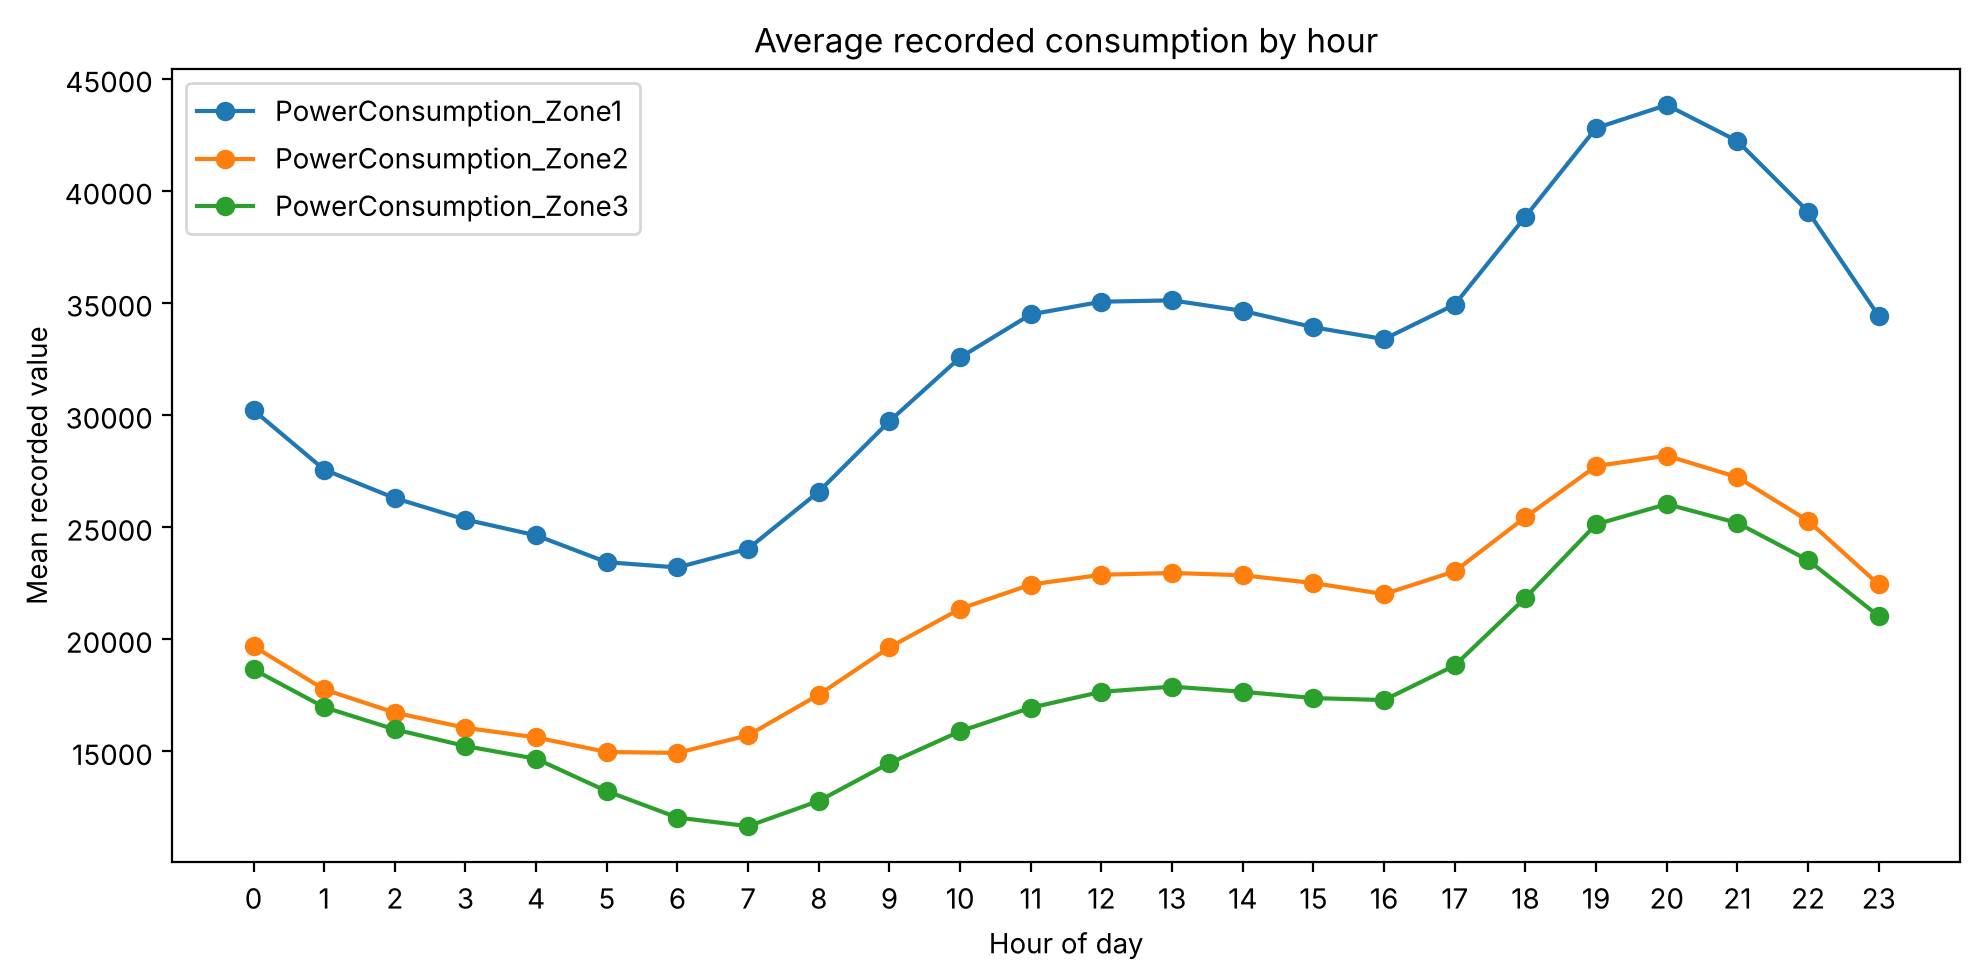

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Hour,,,
0,30217.24,19692.07,18657.22
1,27565.53,17765.08,16970.80
2,26292.69,16730.16,15981.10
3,25338.12,16052.59,15238.61
4,24633.58,15624.08,14671.04
5,23437.58,14974.91,13226.38
6,23203.60,14934.70,12051.60
7,24038.35,15719.12,11667.86
8,26583.26,17529.68,12793.79


In [5]:
hourly_profile = df.groupby("Hour")[zones].mean()
ax = hourly_profile.plot(figsize=(10, 5), marker="o")
ax.set(title="Average recorded consumption by hour",
       xlabel="Hour of day", ylabel="Mean recorded value")
plt.xticks(range(24))
plt.tight_layout()
plt.show()
display(hourly_profile.round(2))


### 5.2 Daily and weekly pattern

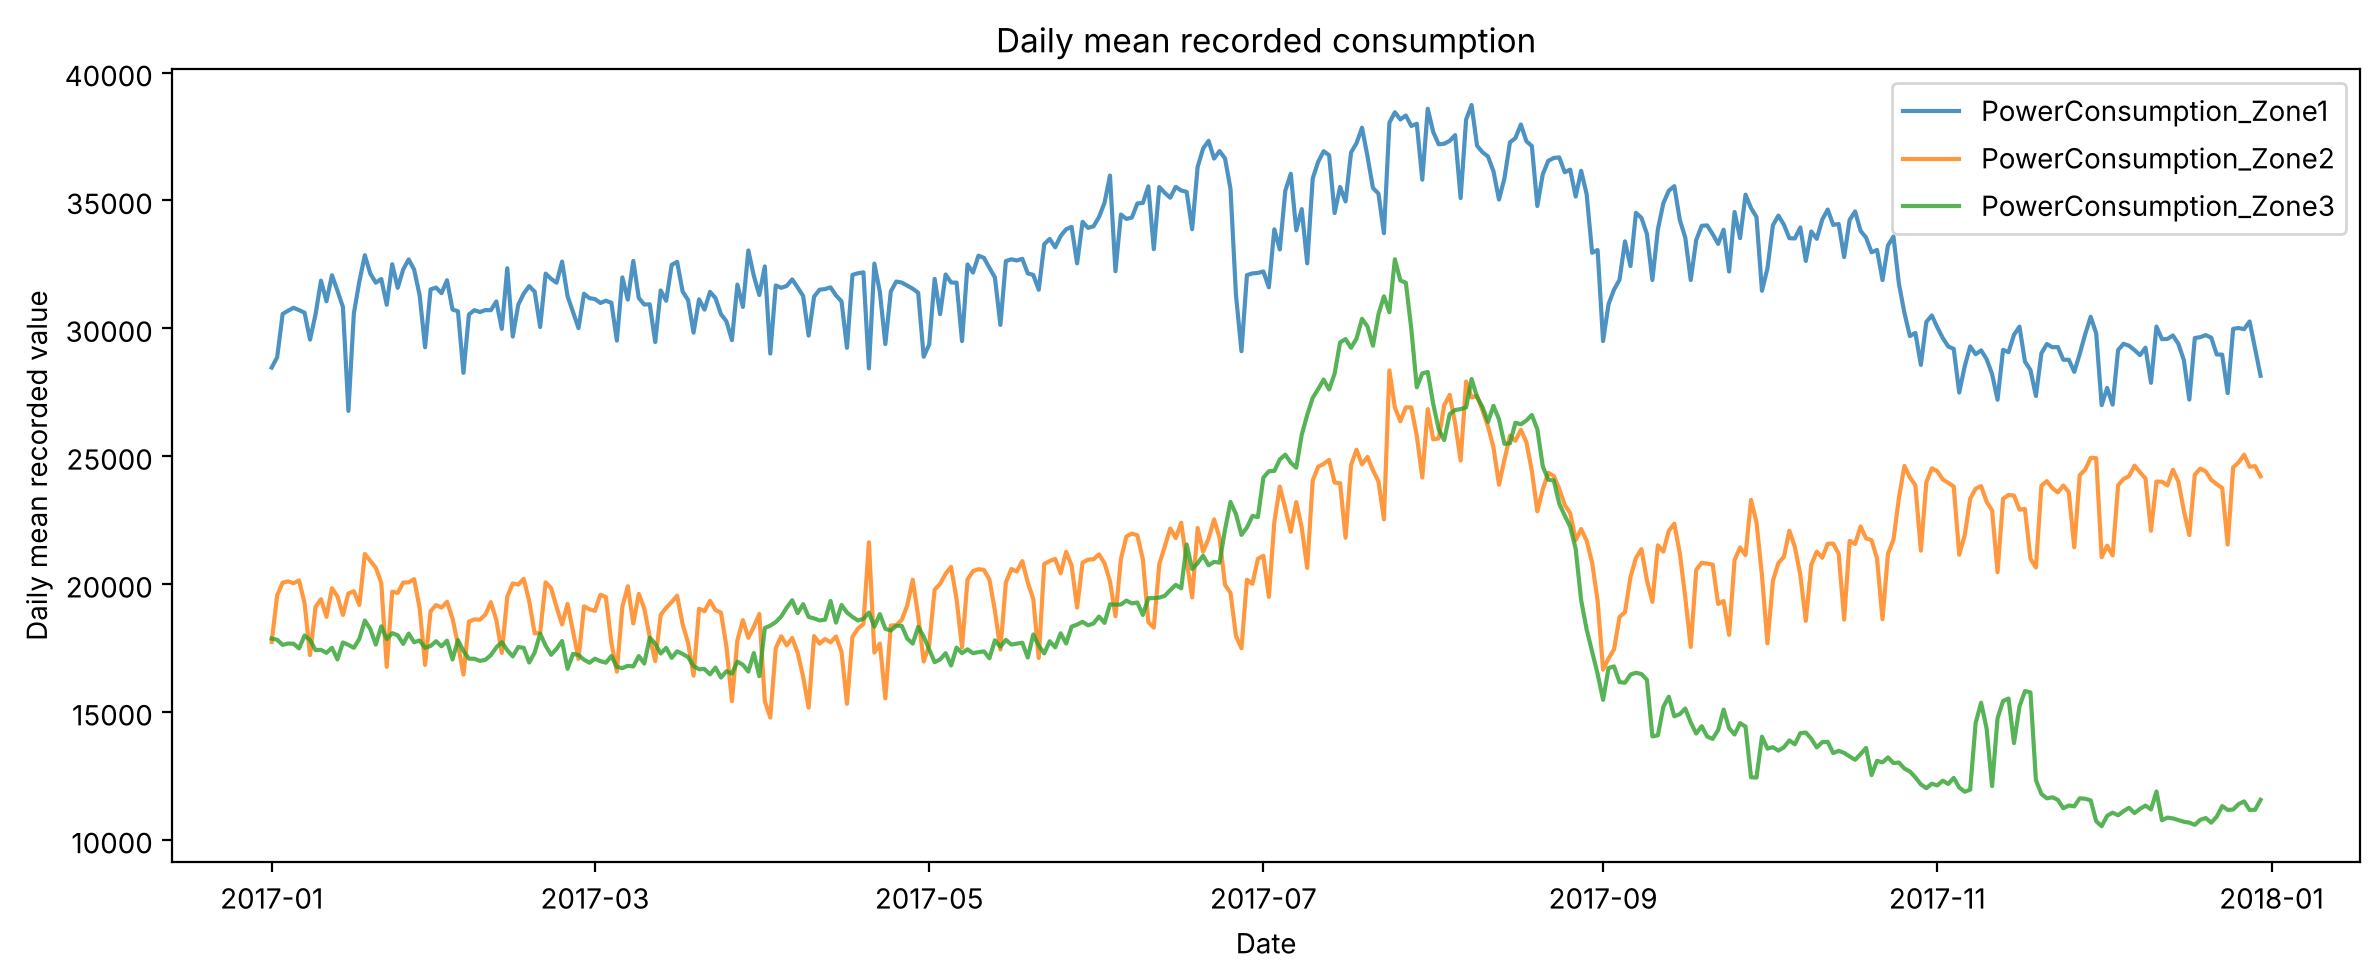

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
DayOfWeek,,,
Monday,32615.41,21280.07,17809.08
Tuesday,32713.03,21518.60,17831.69
Wednesday,32871.76,21627.36,17851.40
Thursday,32842.48,21845.16,17843.69
Friday,32339.00,21461.04,17545.97
Saturday,32253.03,20585.96,18011.19
Sunday,30780.08,18979.38,17954.83


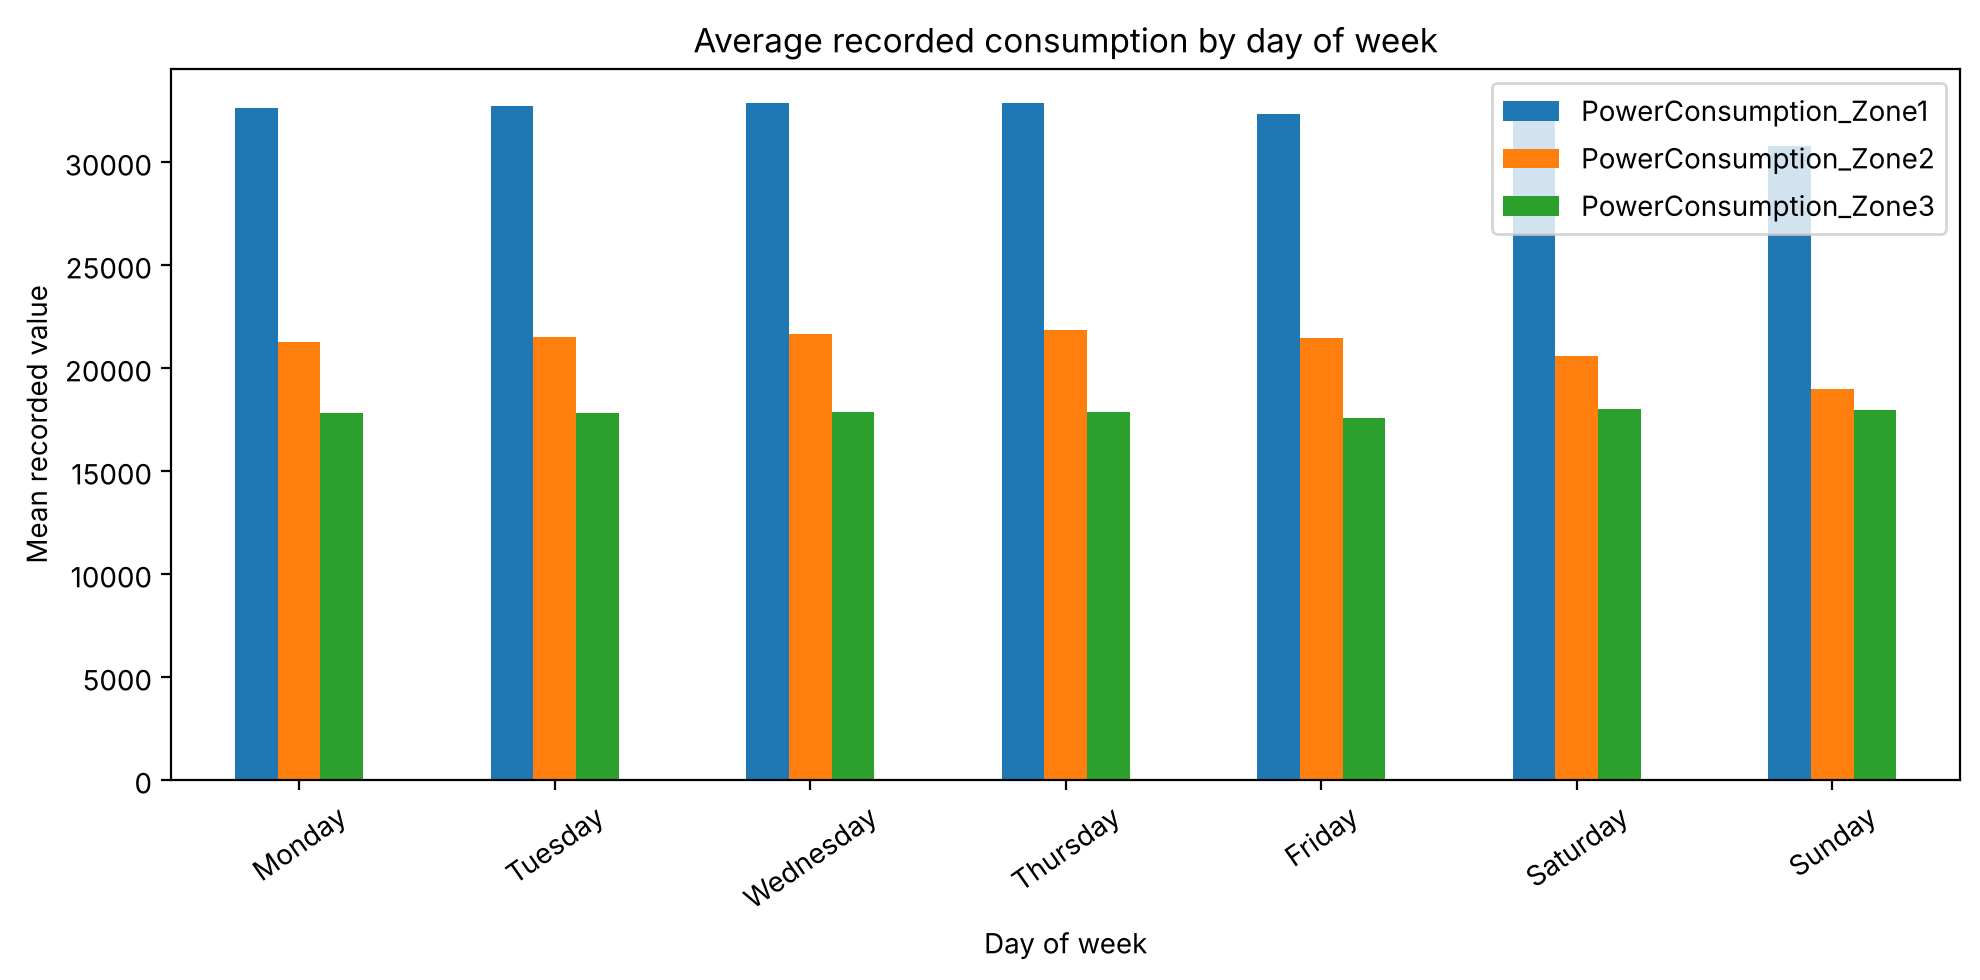

In [6]:
daily_profile = df.groupby("Date")[zones].mean()
ax = daily_profile.plot(figsize=(12, 5), alpha=0.8)
ax.set(title="Daily mean recorded consumption",
       xlabel="Date", ylabel="Daily mean recorded value")
plt.tight_layout()
plt.show()

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday",
                 "Friday", "Saturday", "Sunday"]
weekday_profile = (
    df.groupby("DayOfWeek")[zones].mean().reindex(weekday_order)
)
display(weekday_profile.round(2))
ax = weekday_profile.plot(kind="bar", figsize=(10, 5))
ax.set(title="Average recorded consumption by day of week",
       xlabel="Day of week", ylabel="Mean recorded value")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()


### 5.3 Monthly pattern

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Month,,,
1,31032.49,19394.44,17746.10
2,30985.75,18787.79,17335.00
3,31155.17,18457.94,16947.69
4,31169.77,17633.97,18593.17
5,32396.01,19977.29,17621.10
6,34605.54,20670.93,20430.94
7,35831.55,24147.89,28194.11
8,36435.19,24656.22,24648.89
9,33396.68,20180.43,14922.80


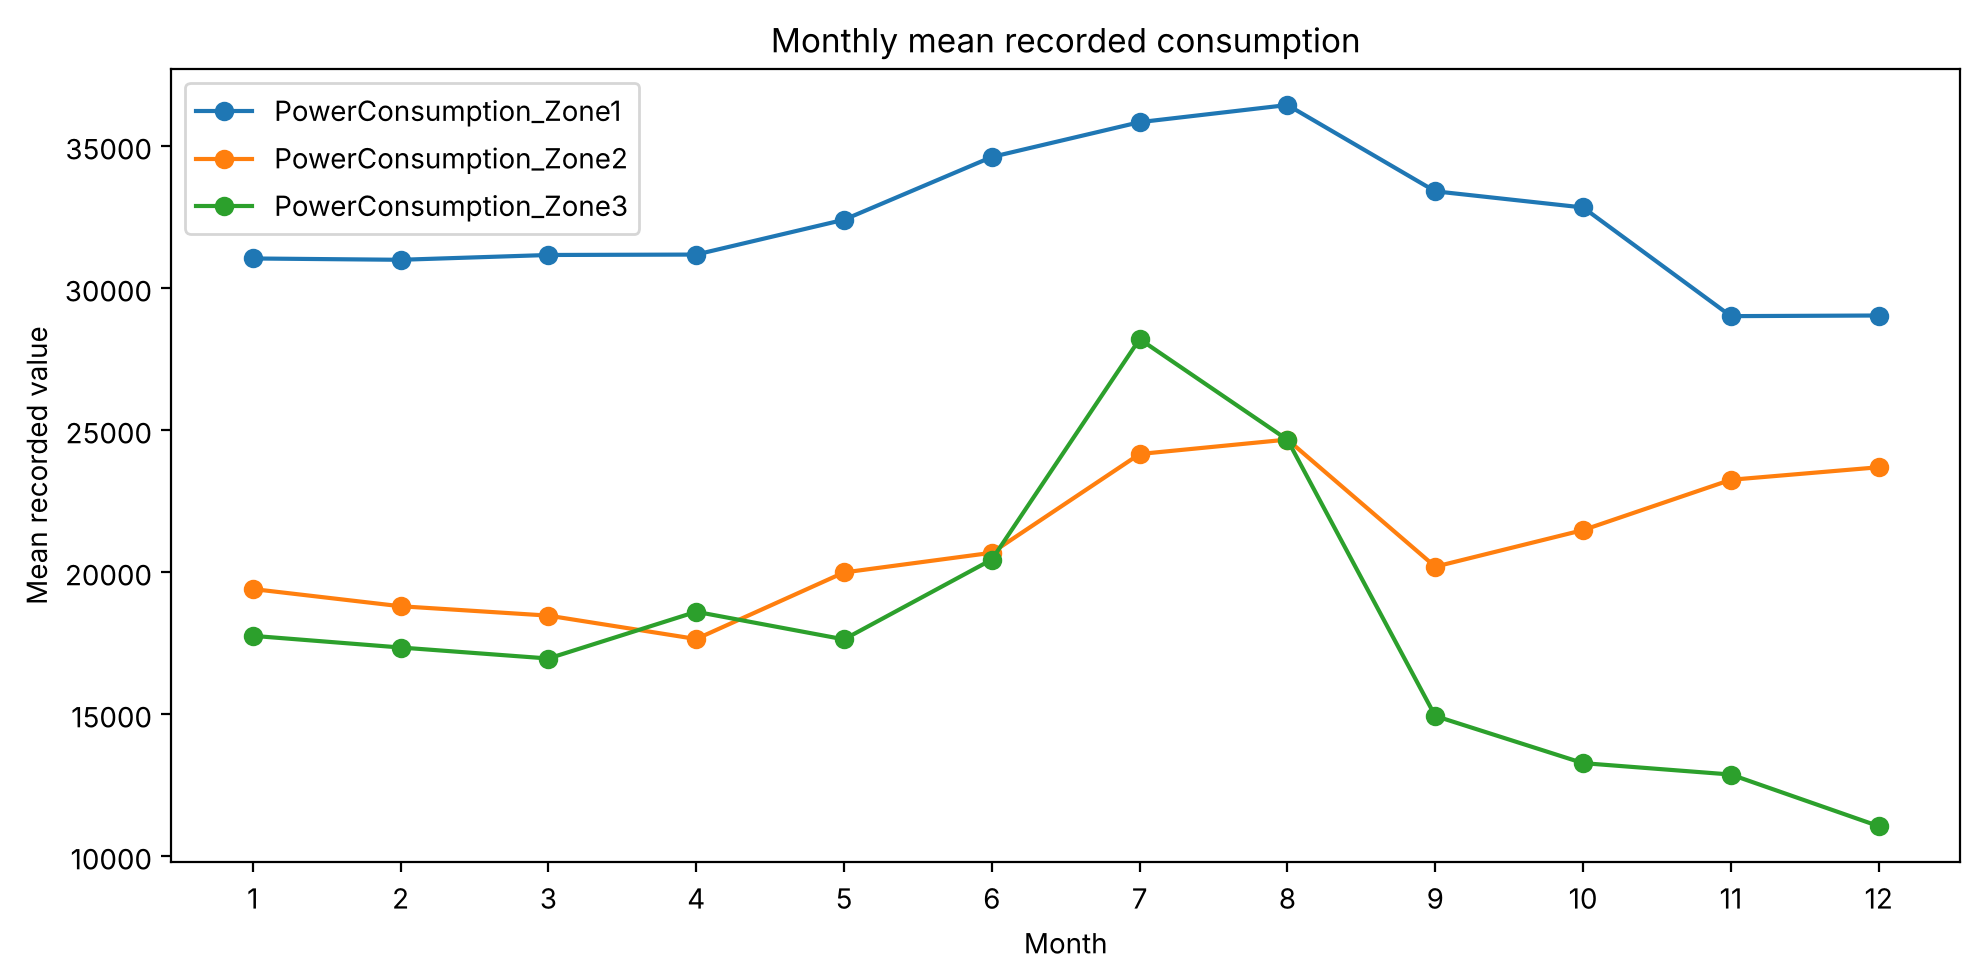

In [7]:
monthly_profile = df.groupby("Month")[zones].mean()
display(monthly_profile.round(2))
ax = monthly_profile.plot(marker="o", figsize=(10, 5))
ax.set(title="Monthly mean recorded consumption",
       xlabel="Month", ylabel="Mean recorded value")
ax.set_xticks(range(1, 13))
plt.tight_layout()
plt.show()


### 5.4 Time-series decomposition with Statsmodels
The daily mean series is decomposed using STL with a period of 7 observations. Since each observation is one day, period=7 represents a weekly cycle. STL separates the series into trend, seasonal and residual components. This is appropriate for examining recurring within-week behaviour. One year of data is not enough to establish a stable multi-year annual seasonal pattern.


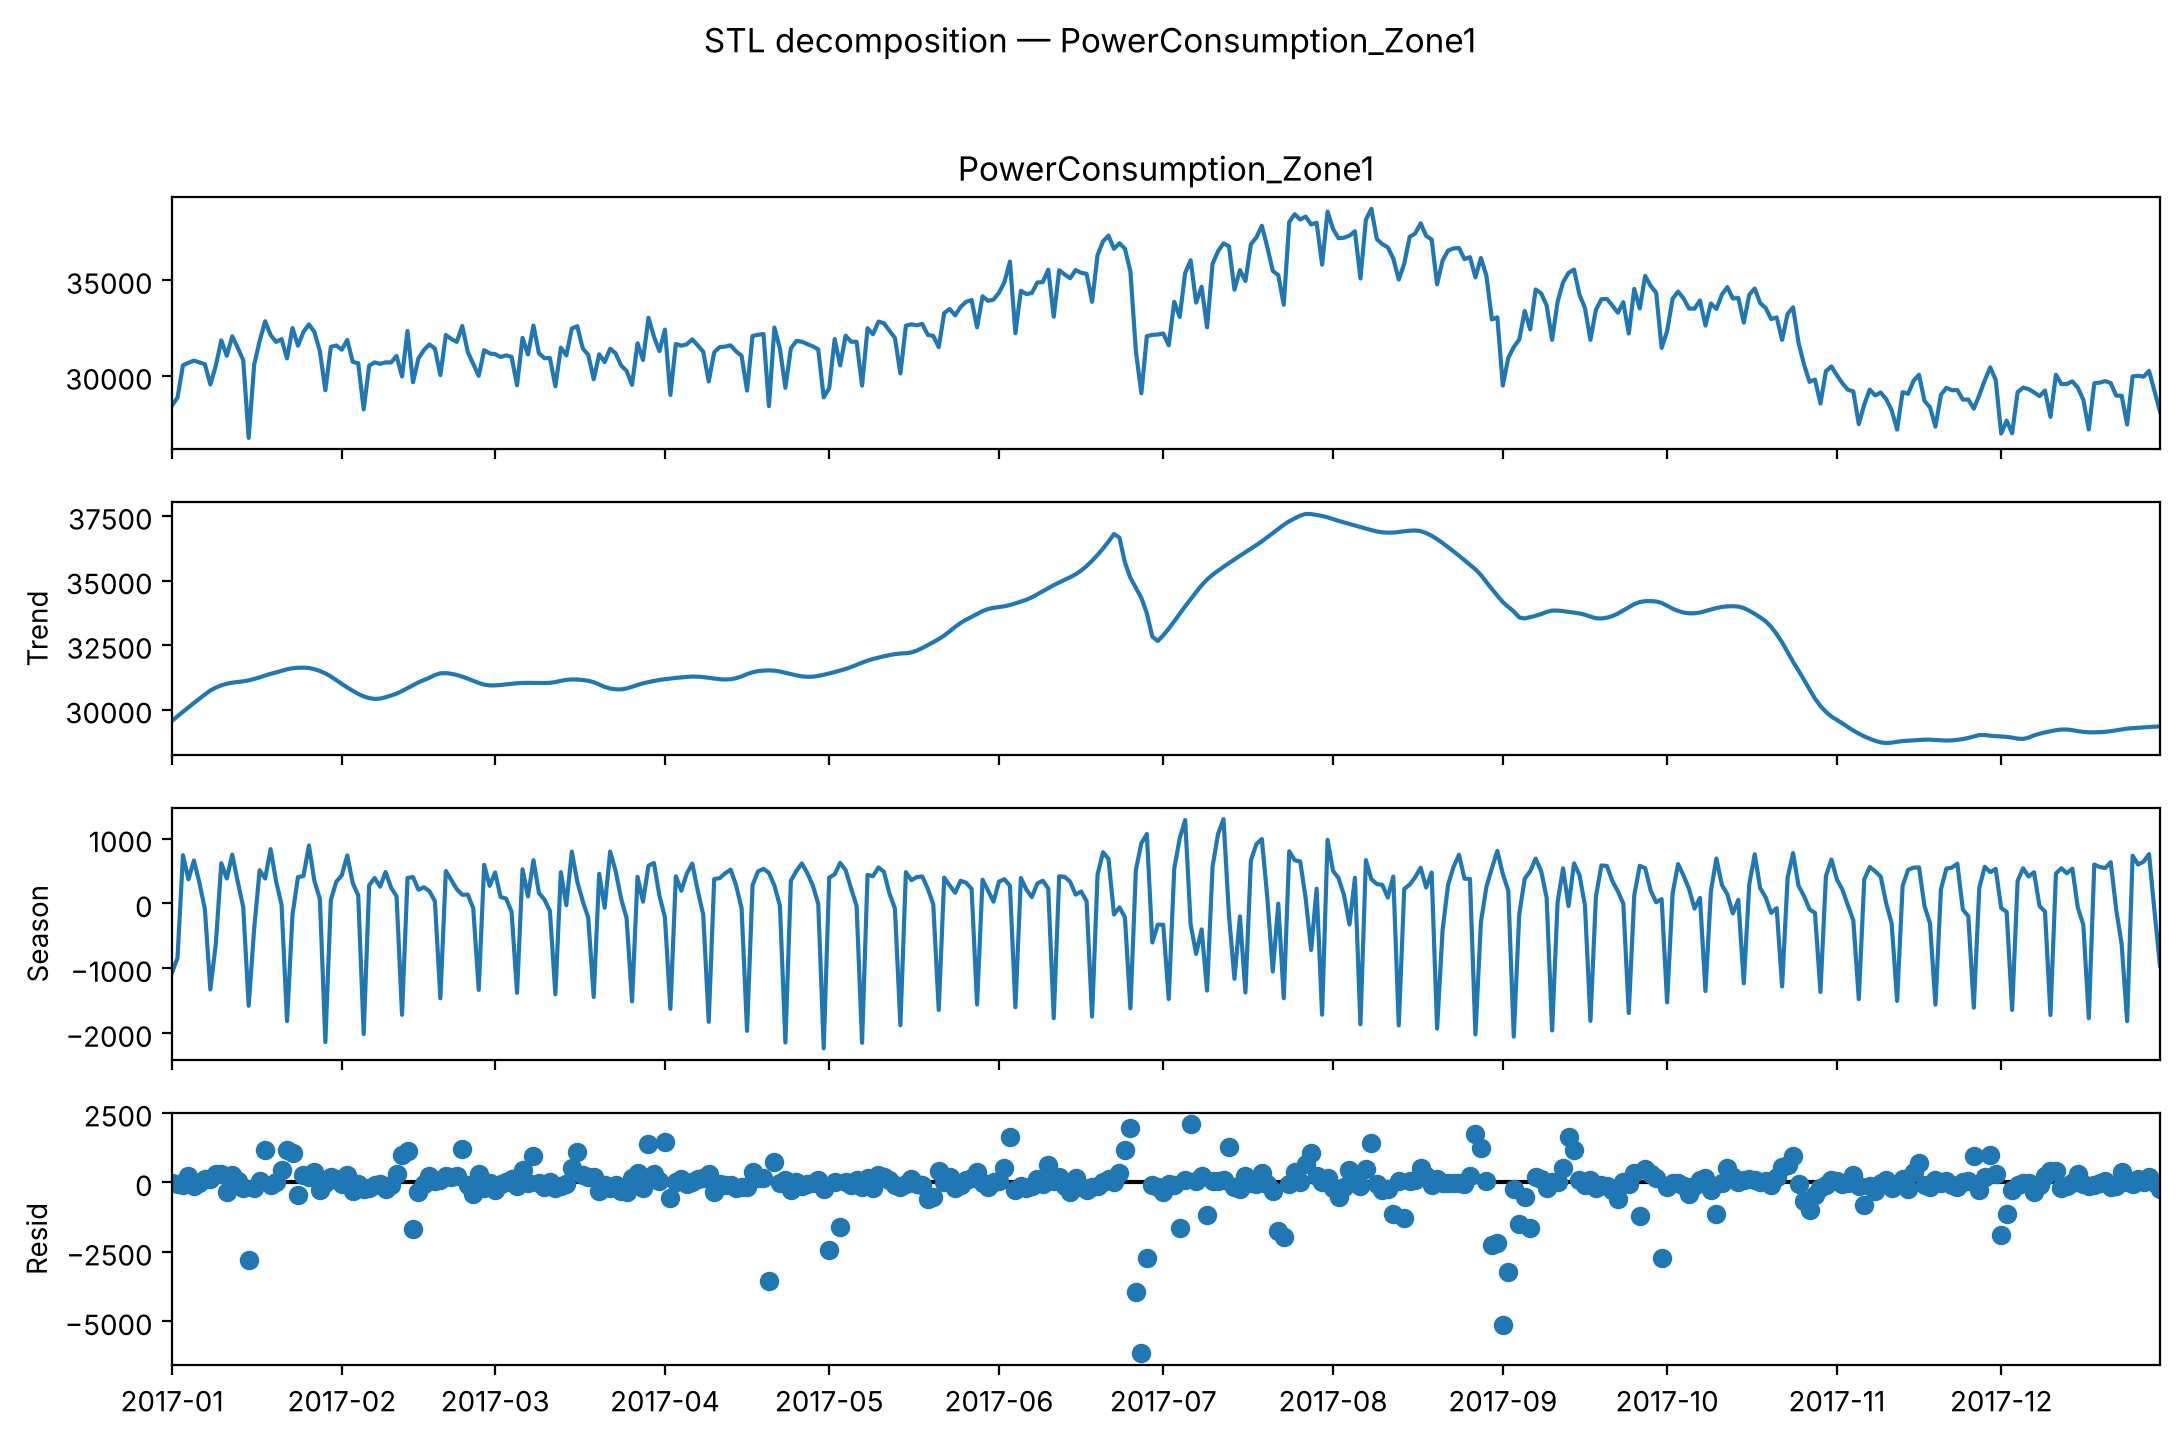

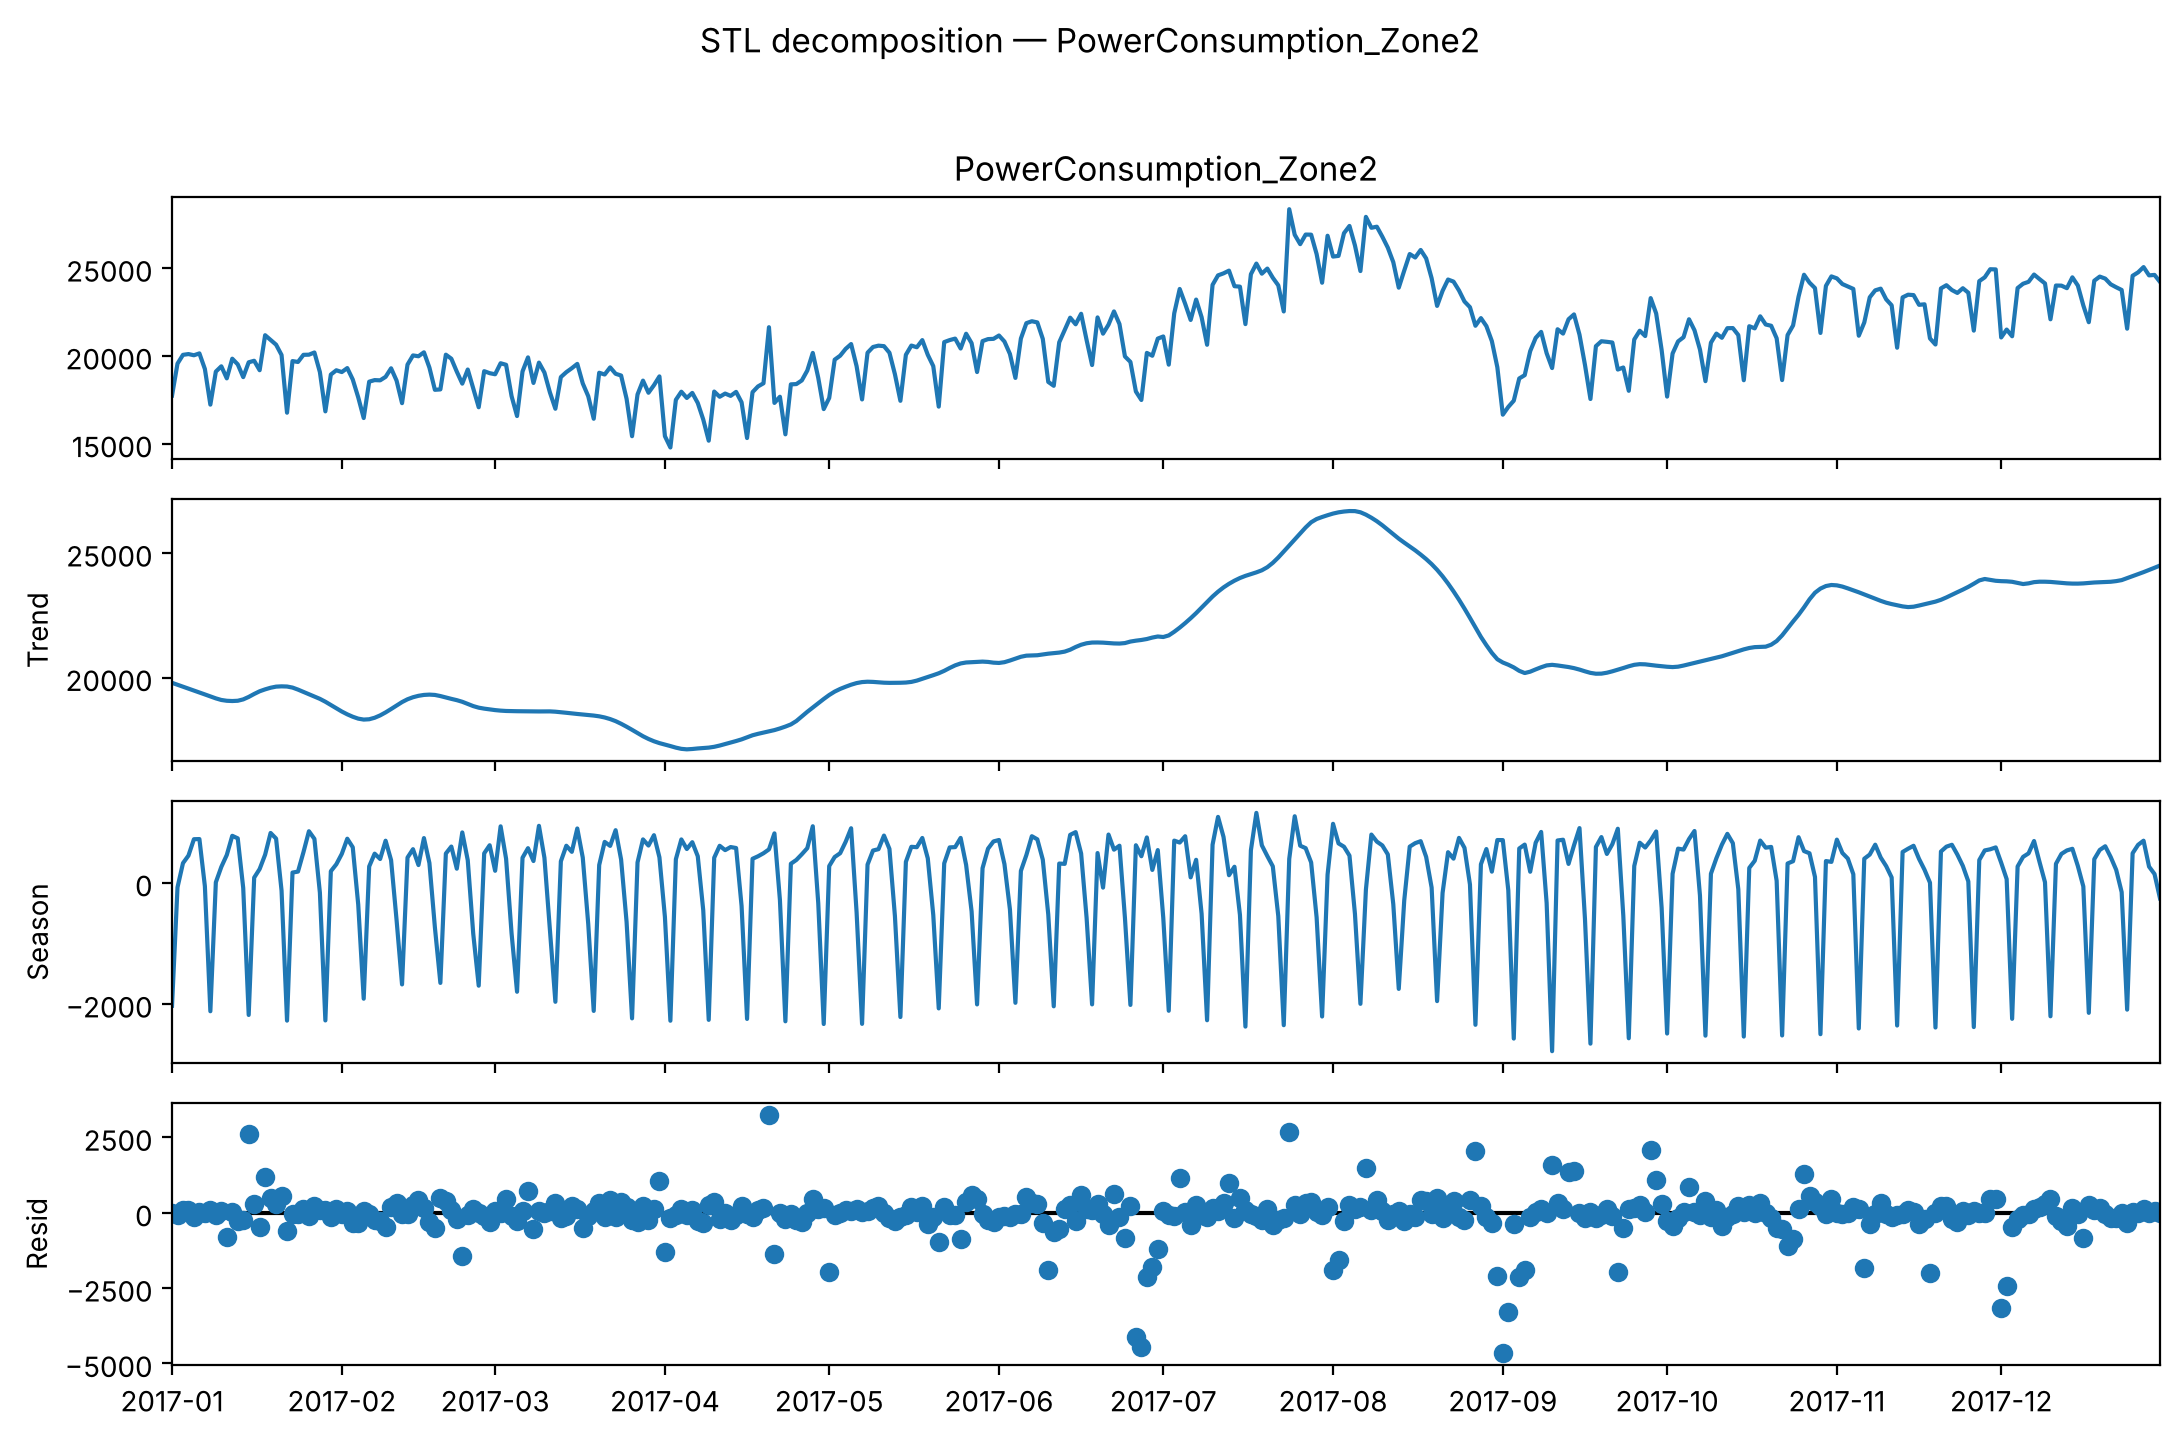

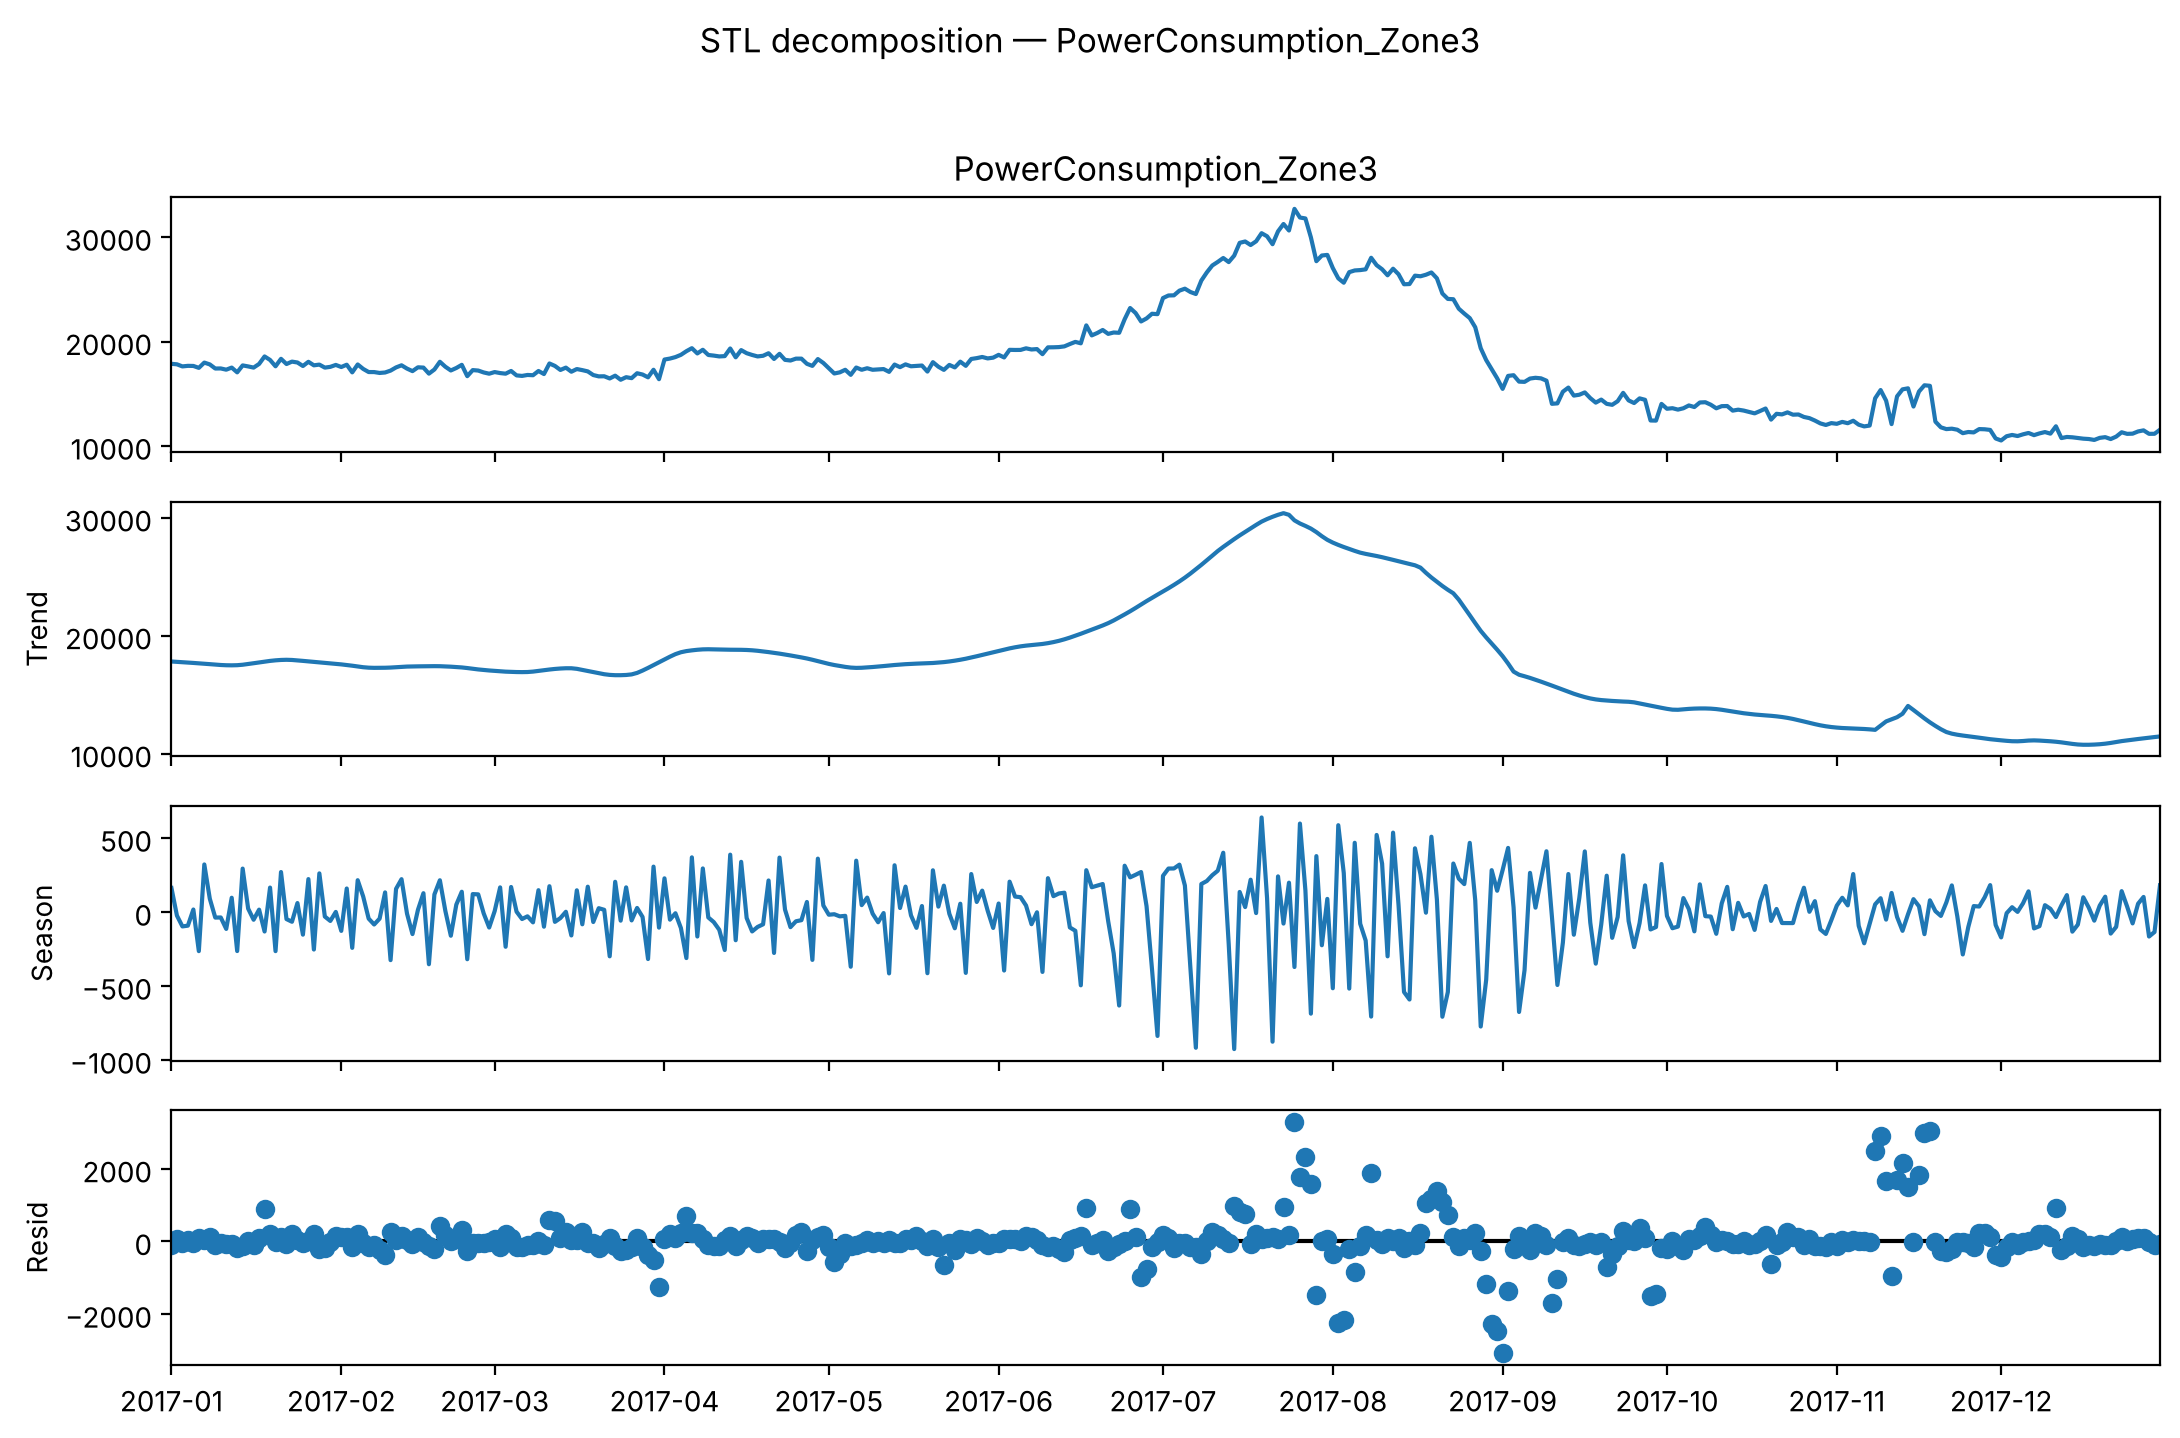

In [8]:
stl_results = {}
for zone in zones:
    result = STL(daily[zone].dropna(), period=7, robust=True).fit()
    stl_results[zone] = result
    fig = result.plot()
    fig.set_size_inches(11, 7)
    fig.suptitle(f"STL decomposition — {zone}", y=1.02)
    plt.tight_layout()
    plt.show()


## 6. Environmental statistical analysis

The analysis below uses **daily averages** rather than treating all 52,416 ten-minute readings as independent observations. This reduces the most obvious pseudo-replication, although daily values can still be serially dependent. Spearman correlation is used because it measures monotonic association and is less sensitive to non-normality and extreme values than Pearson correlation. Correlation does not establish causation.


In [9]:
correlation_rows = []
for zone in zones:
    for variable in environmental:
        rho, p_value = stats.spearmanr(daily[variable], daily[zone], nan_policy="omit")
        correlation_rows.append({
            "Zone": zone, "Environmental variable": variable,
            "Spearman rho": rho, "p-value": p_value
        })

correlations = pd.DataFrame(correlation_rows)
correlations["Holm-adjusted p"] = multipletests(
    correlations["p-value"], method="holm"
)[1]
display(correlations.round(4))


,Zone,Environmental variable,Spearman rho,p-value,Holm-adjusted p
0,PowerConsumption_Zone1,Temperature,0.7238,0.0000,0.0000
1,PowerConsumption_Zone1,Humidity,-0.1147,0.0286,0.0572
2,PowerConsumption_Zone1,WindSpeed,0.3804,0.0000,0.0000
3,PowerConsumption_Zone2,Temperature,0.3944,0.0000,0.0000
4,PowerConsumption_Zone2,Humidity,-0.1287,0.0140,0.0421
5,PowerConsumption_Zone2,WindSpeed,0.1971,0.0002,0.0008
6,PowerConsumption_Zone3,Temperature,0.4674,0.0000,0.0000
7,PowerConsumption_Zone3,Humidity,-0.1078,0.0397,0.0572
8,PowerConsumption_Zone3,WindSpeed,0.1415,0.0069,0.0274


In [10]:
# Plotly scatter plots of daily averages, with one trace per zone.
daily_long = daily.reset_index().melt(
    id_vars=["Datetime"] + environmental,
    value_vars=zones, var_name="Zone", value_name="Recorded consumption"
)
for variable in environmental:
    fig = px.scatter(
        daily_long, x=variable, y="Recorded consumption",
        color="Zone", opacity=0.55,
        title=f"Daily mean consumption and {variable}"
    )
    fig.update_layout(template="plotly_white")
    fig.show()


## 7. Comparative zone analysis

The three zone series are measured at the same timestamps. For a paired comparison, aggregate to daily means and use the **Friedman test**, a non-parametric test for differences across three or more related groups. This avoids treating the three zones on a given day as independent samples.

Null hypothesis: the three zones have the same distribution of daily ranks.
Alternative hypothesis: at least one zone differs.


In [11]:
friedman = stats.friedmanchisquare(*(daily[zone].dropna() for zone in zones))
n_days = daily[zones].dropna().shape[0]
kendalls_w = friedman.statistic / (n_days * (len(zones) - 1))
print("Friedman statistic:", friedman.statistic)
print("p-value:", friedman.pvalue)
print("Kendall's W:", kendalls_w)

# Follow-up paired Wilcoxon tests, with Holm correction for three comparisons.
from itertools import combinations
pairwise_rows = []
for first, second in combinations(zones, 2):
    test = stats.wilcoxon(daily[first], daily[second])
    pairwise_rows.append({
        "Zone 1": first, "Zone 2": second,
        "Wilcoxon statistic": test.statistic, "p-value": test.pvalue
    })
pairwise = pd.DataFrame(pairwise_rows)
pairwise["Holm-adjusted p"] = multipletests(pairwise["p-value"], method="holm")[1]
display(pairwise)


Friedman statistic: 586.6373626373634
p-value: 4.1050198750286526e-128
Kendall's W: 0.8058205530733014


,Zone 1,Zone 2,Wilcoxon statistic,p-value,Holm-adjusted p
0,PowerConsumption_Zone1,PowerConsumption_Zone2,0.0,2.086755e-61,6.260264e-61
1,PowerConsumption_Zone1,PowerConsumption_Zone3,0.0,2.086755e-61,6.260264e-61
2,PowerConsumption_Zone2,PowerConsumption_Zone3,12182.0,1.186650e-25,1.186650e-25


### Variability comparison
Use both standard deviation (absolute variability) and coefficient of variation (relative variability). The zone with the highest mean is not necessarily the zone with the greatest relative variability.


In [12]:
variability = pd.DataFrame({
    "Mean": df[zones].mean(),
    "Standard deviation": df[zones].std(),
    "Coefficient of variation": df[zones].std() / df[zones].mean()
})
display(variability.round(3))


,Mean,Standard deviation,Coefficient of variation
PowerConsumption_Zone1,32344.971,7130.563,0.220
PowerConsumption_Zone2,21042.509,5201.466,0.247
PowerConsumption_Zone3,17835.406,6622.165,0.371


## 8. Interpretation, limitations and recommendations

Important limitations:
- Only one year is supplied, and the final day (31 December) is absent.
- The data dictionary's description of `GeneralDiffuseFlows` and `DiffuseFlows` is unclear and appears inconsistent with their names. Do not interpret their physical meaning without clarification.
- The consumption unit is labelled kWh, but the interval basis is not established in the brief.
- Daily aggregation reduces but does not eliminate serial dependence.
- Temperature, humidity and wind speed may be confounded by season, time of day, occupancy, business activity and other omitted factors.
- Zone 3 shows a pronounced reduction from July–August to September–December. Treat this as a pattern requiring investigation, not automatically as a real operational change or data error.
- The data represent recorded consumption, not a causal experiment.

## 9. Reproducibility checklist

1. Install the packages listed in the README.
2. Put both CSV files in the `data/` folder.
3. Run every notebook cell from top to bottom.
4. Confirm that the data-quality checks match the documented results.
5. Save the generated charts and statistical tables with the report.
6. Record any changes to the source data, code or assumptions.
